# Callable Range Accrual

This notebook prices the **callable SOFR range accrual** of the paper (Table 1) with the public data of `Data/USD`
(downloaded by `download_data.py`, see `Data/USD/README.md`). It follows the building blocks of the paper:

| Block | Section | Status here |
|---|---|---|
| 0. Product | §2 | term sheet, exact schedule (calendar, cut-off, notice), payoff, historical backtest |
| I. Foundations | §4 | Treasury bond measures (validated against QuantLib), carry / roll-down, PCA |
| II. SOFR curve | §5 | **proxy**: Treasury curve + constant spread (no free SOFR futures / OIS quotes) |
| III. Volatility | §6 | **not available** (options on SR3 are CME data): realized Treasury vols instead |
| IV. Model | §7 | Hull-White **one-factor** as a placeholder for the two-factor model |
| V. Pricing | §8 | replication, Monte Carlo, Longstaff-Schwartz, exact grid (1F benchmark) |
| VI. Risk | §9 | DV01, key-rate DV01, vega, gamma; no hedge backtest (needs CME history) |

> **What is real and what is assumed.** SOFR fixings, the Fed funds target range, Treasury par yields, FOMC dates
> and holidays are market data. The SOFR **curve** is a proxy (Treasury curve shifted to the overnight SOFR) and the
> **volatility** is calibrated on realized Treasury yield volatility (historical measure, not implied). Every result
> that depends on these two assumptions is labelled as such.

**Plugging in the two-factor model.** The Monte Carlo and Longstaff-Schwartz pricer (`range_accrual_pricer.monte_carlo`)
only calls two methods of the model, which is the interface of `HullWhite` (`Fixed_Income_Models/hull_white_1F.py`):
- `simulate(times, n_paths, seed, antithetic) -> (states, D)`: `states[k]` is the state at `times[k]` (an array of
  shape `(n_times, n_paths)`, or a tuple of such arrays for several factors) and `D[k]` the discount factor
  $e^{-\int_0^{t_k} r}$ on each path;
- `bond_price(t, T, state)`: $P(t,T)$ given the state at $t$.

The grid pricer `HullWhiteGridPricer` is exact but specific to the one-factor model: it stays as the benchmark of the
Monte Carlo.

In [1]:
import os, sys, time
sys.path.append(os.path.abspath(os.path.join("..", "..")))   # Projets : Fixed_Income_Models package

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from scipy.optimize import least_squares
import QuantLib as ql

from usd_market import (load_sofr, load_target_range, load_treasury, load_fomc, USGovCalendar, treasury_curve,
                        sofr_proxy_curve, year_fraction)
from range_accrual import CallableRangeAccrual
from range_accrual_pricer import (NoteGrid, replication_value, hull_white_normal_vol, monte_carlo,
                                  HullWhiteGridPricer)
from Fixed_Income_Models import HullWhite, YieldCurve

pd.set_option("display.float_format", lambda x: f"{x:,.6g}")

# Chart style : fixed categorical order, recessive grid and axes, 2px lines
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.prop_cycle": cycler(color=COLORS), "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "lines.linewidth": 2, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "axes.titlesize": 11, "axes.titleweight": "bold"})

tenor_label = lambda t: f"{12 * t:.0f}M" if t < 1 else f"{t:g}Y"

sofr_data, target, treasury, fomc = load_sofr(), load_target_range(), load_treasury(), load_fomc()
sofr = sofr_data["SOFR"]
calendar = USGovCalendar()
VALUATION = treasury.index[-1]                      # last date with Treasury yields and SOFR
print(f"Valuation date {VALUATION.date()} | last SOFR {sofr.index[-1].date()} ({100 * sofr.iloc[-1]:.2f}%) | "
      f"target range {100 * target['lower'].loc[VALUATION]:.2f}% - {100 * target['upper'].loc[VALUATION]:.2f}%")

Valuation date 2026-10-02 | last SOFR 2026-10-05 (3.89%) | target range 3.75% - 4.00%


## 1. The product (§2)

Every calendar day $d$ of $(T_{j-1}, T_j]$ accrues $(R_d + s)\,\mathbf 1_{\{L \le R_d \le U\}}/360$, where $R_d$ is
the SOFR of the last business day $\le d$, frozen at the cut-off (5 business days before $T_j$). The issuer can call
at par on each coupon date from the end of year 1, with 10 business days' notice. The note is issued on the valuation
date, so the first fixing (the SOFR of the issue date) is already known.

In [2]:
note = CallableRangeAccrual(VALUATION, calendar, maturity_years=3, notional=10_000_000, spread=0.0125,
                            lower=0.03, upper=0.0425)
N = note.notional
print(note)
note.schedule_frame()

CallableRangeAccrual(2026-10-02 -> 2029-10-02, SOFR + 125bp in [3.00%, 4.25%], callable from year 1 (8 dates))


,start,end (payment),cut-off,calendar days,distinct fixings,call date,notice date
period,,,,,,,
1,2026-10-02,2027-01-04,2026-12-24,94,57,False,None
2,2027-01-04,2027-04-02,2027-03-25,88,56,False,None
3,2027-04-02,2027-07-02,2027-06-25,91,59,False,None
4,2027-07-02,2027-10-04,2027-09-27,94,60,True,2027-09-20
5,2027-10-04,2028-01-03,2027-12-27,91,56,True,2027-12-17
6,2028-01-03,2028-04-03,2028-03-27,91,58,True,2028-03-20
7,2028-04-03,2028-07-03,2028-06-26,91,57,True,2028-06-16
8,2028-07-03,2028-10-02,2028-09-25,91,59,True,2028-09-18
9,2028-10-02,2029-01-02,2028-12-22,92,57,True,2028-12-15


The coupon of a period is a weighted sum over its **distinct fixing dates**: a Friday fixing counts for 3 days, and
the cut-off fixing for every day after it (12 days over the 2026 year-end, which contains two holidays).

In [3]:
p = note.periods[0]
pd.DataFrame({"fixing date": p["fixing_dates"].date, "calendar days using it": p["weights"]}).tail(8)

,fixing date,calendar days using it
49,2026-12-15,1
50,2026-12-16,1
51,2026-12-17,1
52,2026-12-18,3
53,2026-12-21,1
54,2026-12-22,1
55,2026-12-23,1
56,2026-12-24,12


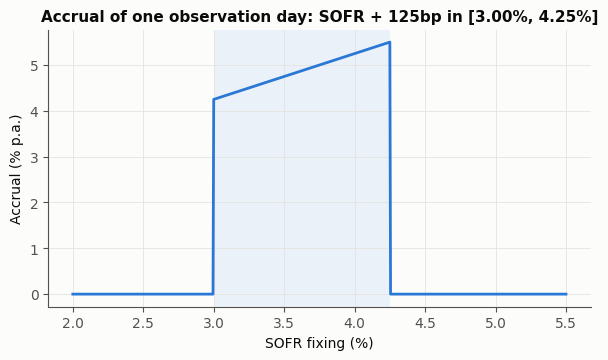

In [4]:
rates = np.linspace(0.02, 0.055, 701)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.axvspan(100 * note.lower, 100 * note.upper, color=COLORS[0], alpha=0.08, lw=0)
ax.plot(100 * rates, 100 * note.accrual(rates), color=COLORS[0])
ax.set_xlabel("SOFR fixing (%)"); ax.set_ylabel("Accrual (% p.a.)")
ax.set_title(f"Accrual of one observation day: SOFR + {1e4 * note.spread:.0f}bp in [{100 * note.lower:.2f}%, {100 * note.upper:.2f}%]")
plt.show()

## 2. Market data (§3)

### 2.1 SOFR and the Fed funds target range

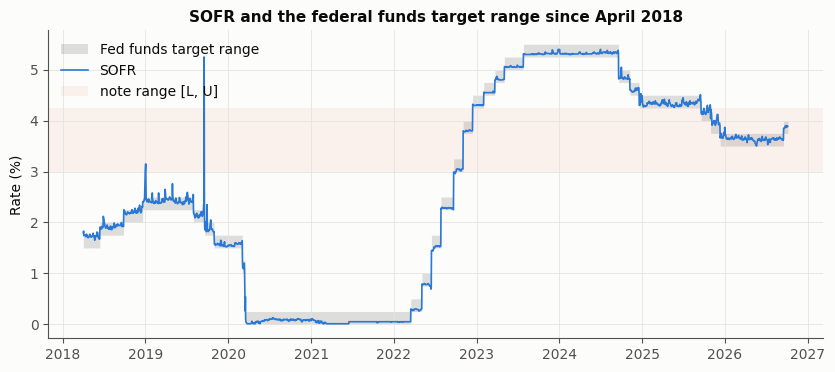

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
tr = target.loc[sofr.index[0]:]
ax.fill_between(tr.index, 100 * tr["lower"], 100 * tr["upper"], color=MUTED, alpha=0.18, lw=0, label="Fed funds target range")
ax.plot(sofr.index, 100 * sofr, color=COLORS[0], lw=1.2, label="SOFR")
ax.axhspan(100 * note.lower, 100 * note.upper, color=COLORS[1], alpha=0.07, lw=0, label="note range [L, U]")
ax.set_ylabel("Rate (%)"); ax.set_title("SOFR and the federal funds target range since April 2018")
ax.legend(loc="upper left"); plt.show()

**Spikes.** SOFR sometimes prints above the top of the target range (month-ends, quarter-ends, tax dates, the
September 2019 repo crisis): a single day can leave the range even when the policy rate is well inside it.

In [6]:
upper = target["upper"].reindex(sofr.index)
spread_to_top = 1e4 * (sofr - upper)
above = spread_to_top[spread_to_top > 0]
month_end = above.index.is_month_end | (above.index + pd.offsets.BDay(1)).month != above.index.month
print(f"SOFR above the top of the target range on {len(above)} of {len(sofr)} days "
      f"({100 * np.mean(month_end):.0f}% of them on the last business day of a month)")
above.sort_values(ascending=False).head(8).rename("SOFR - top of range (bp)").to_frame()

SOFR above the top of the target range on 62 of 2126 days (95% of them on the last business day of a month)


,SOFR - top of range (bp)
Date,
2019-09-17,300
2019-01-02,65
2018-12-31,50
2019-09-30,35
2019-09-18,30
2020-03-17,29
2019-04-30,26
2025-10-31,22


### 2.2 Historical backtest of the note

What would this exact term sheet (range [3.00%, 4.25%], SOFR + 1.25%) have paid if issued at the start of each
quarter since 2018? The share of days in range shows how the note depends on the **level** of the policy rate: it pays
nothing when the Fed is at zero (2020-2021) or above 4.25% (2023-2025).

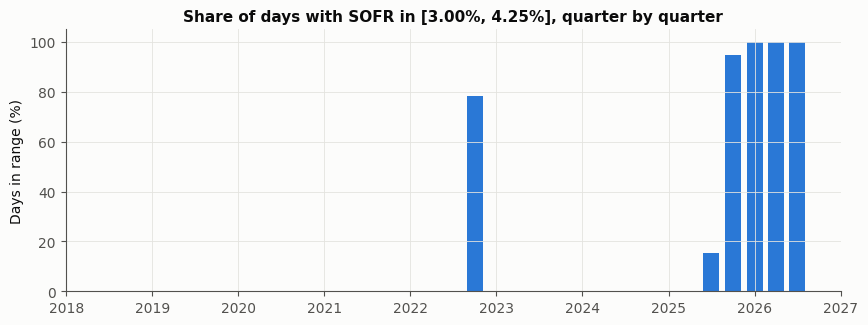

Average coupon rate over 33 quarters : 0.73% p.a. (vs 2.72% for plain SOFR)


In [7]:
quarters = pd.date_range("2018-07-01", sofr.index[-1], freq="QS")
rows = []
for q in quarters:
    start = calendar.modified_following(q)
    one_period = CallableRangeAccrual(start, calendar, maturity_years=0.25, non_call_years=0, callable=False)
    try:
        realized = one_period.realized_coupons(sofr)
    except ValueError:
        continue
    if len(realized):
        rows.append({"quarter": start, "share in range": realized["days in range"].iloc[0] / realized["days"].iloc[0],
                     "coupon rate (% p.a.)": realized["coupon rate (% p.a.)"].iloc[0]})
backtest = pd.DataFrame(rows).set_index("quarter")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(backtest.index, 100 * backtest["share in range"], width=70, color=COLORS[0])
ax.set_ylabel("Days in range (%)"); ax.set_title("Share of days with SOFR in [3.00%, 4.25%], quarter by quarter")
plt.show()
print(f"Average coupon rate over {len(backtest)} quarters : {backtest['coupon rate (% p.a.)'].mean():.2f}% p.a. "
      f"(vs {100 * sofr.loc[backtest.index[0]:].mean():.2f}% for plain SOFR)")

In [8]:
issued_2023 = CallableRangeAccrual("2023-01-03", calendar)
issued_2023.realized_coupons(sofr)

,period,start,end,days,days in range,coupon (% of N),coupon rate (% p.a.)
0,1,2023-01-03,2023-04-03,90,0,0,0
1,2,2023-04-03,2023-07-03,91,0,0,0
2,3,2023-07-03,2023-10-03,92,0,0,0
3,4,2023-10-03,2024-01-03,92,0,0,0
4,5,2024-01-03,2024-04-03,91,0,0,0
5,6,2024-04-03,2024-07-03,91,0,0,0
6,7,2024-07-03,2024-10-03,92,0,0,0
7,8,2024-10-03,2025-01-03,92,0,0,0
8,9,2025-01-03,2025-04-03,90,0,0,0
9,10,2025-04-03,2025-07-03,91,0,0,0


## 3. Fixed income foundations on the Treasury curve (§4)

### 3.1 Bootstrapped Treasury curve
Bills (1M to 1Y) are bond-equivalent yields, treated as semi-annually compounded zero rates; notes and bonds (2Y to 30Y)
are par bonds with semi-annual coupons. Monotone convex interpolation; every input is repriced exactly.

In [9]:
tsy_curve, tsy_boot = treasury_curve(VALUATION, treasury)
tsy_boot.report()

,instrument,maturity,quote (%),implied (%),residual (bp),zero rate (%)
0,zero-coupon,0.0833333,4.04,4.04,0,3.99974
1,zero-coupon,0.25,4.19,4.19,0,4.14671
2,zero-coupon,0.5,4.27,4.27,0,4.22506
3,zero-coupon,1,4.46,4.46,0,4.411
4,par bond,2,4.83,4.83,6.93889e-14,4.78267
5,par bond,3,4.96,4.96,1.38778e-13,4.9129
6,par bond,5,5.06,5.06,0,5.01311
7,par bond,7,5.17,5.17,1.38778e-13,5.13173
8,par bond,10,5.28,5.28,-2.08167e-13,5.25507
9,par bond,20,5.67,5.67,6.93889e-14,5.76352


### 3.2 Bond pricing, yield and risk measures
A 5-year Treasury with a 4.50% semi-annual coupon issued on the valuation date (no accrued interest, clean = dirty).
Price from the curve, yield to maturity by Newton, Macaulay and modified duration, DV01 and convexity. Validation:
the same bond in QuantLib (ACT/ACT ICMA, US government bond calendar) gives the same price, yield, duration and
convexity.

In [10]:
coupon, maturity, freq = 0.045, 5, 2
times = np.arange(1, maturity * freq + 1) / freq
flows = np.full(len(times), 100 * coupon / freq); flows[-1] += 100

price_curve = float(np.sum(flows * tsy_curve.discount(times)))
price_y = lambda y: np.sum(flows / (1 + y / freq)**(freq * times))

def ytm(price, y=0.04):                                     # Newton on the semi-annual yield
    for _ in range(50):
        dp = np.sum(-times * flows / (1 + y / freq)**(freq * times + 1))
        y -= (price_y(y) - price) / dp
    return y

y = ytm(price_curve)
w = flows / (1 + y / freq)**(freq * times) / price_curve
macaulay = np.sum(w * times)
modified = macaulay / (1 + y / freq)
dv01 = modified * price_curve * 1e-4
convexity = np.sum(w * times * (times + 1 / freq)) / (1 + y / freq)**2

# QuantLib validation
today = ql.Date(VALUATION.day, VALUATION.month, VALUATION.year); ql.Settings.instance().evaluationDate = today
qcal = ql.UnitedStates(ql.UnitedStates.GovernmentBond)
schedule = ql.Schedule(today, today + ql.Period(maturity, ql.Years), ql.Period(ql.Semiannual), qcal, ql.Unadjusted,
                       ql.Unadjusted, ql.DateGeneration.Backward, False)
dc = ql.ActualActual(ql.ActualActual.ISMA, schedule)
bond = ql.FixedRateBond(0, 100, schedule, [coupon], dc)
rate = ql.InterestRate(y, dc, ql.Compounded, ql.Semiannual)
pd.DataFrame({"this notebook": [price_curve, 100 * y, macaulay, modified, dv01, convexity],
              "QuantLib": [ql.BondFunctions.cleanPrice(bond, rate),
                           100 * ql.BondFunctions.bondYield(bond, ql.BondPrice(price_curve, ql.BondPrice.Clean), dc, ql.Compounded, ql.Semiannual),
                           ql.BondFunctions.duration(bond, rate, ql.Duration.Macaulay),
                           ql.BondFunctions.duration(bond, rate, ql.Duration.Modified),
                           ql.BondFunctions.basisPointValue(bond, rate) * -1,
                           ql.BondFunctions.convexity(bond, rate)]},
             index=["price", "yield (%)", "Macaulay duration", "modified duration", "DV01 (per 100)", "convexity"])

,this notebook,QuantLib
price,97.5463,97.5454
yield (%),5.06161,5.06141
Macaulay duration,4.52575,4.52595
modified duration,4.41404,4.41424
DV01 (per 100),0.0430573,0.0430588
convexity,22.878,22.8787


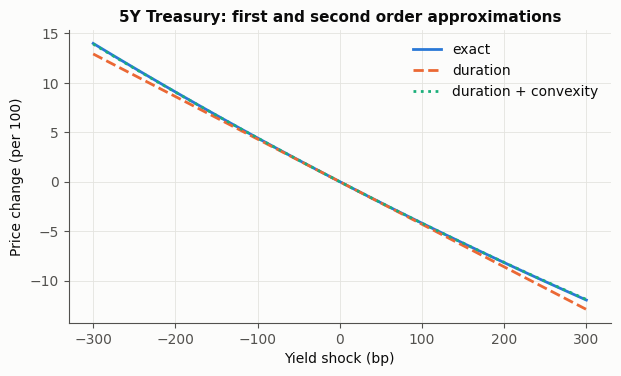

In [11]:
shocks = np.linspace(-300, 300, 61)
exact = np.array([price_y(y + b * 1e-4) for b in shocks]) - price_curve
order1 = -modified * price_curve * shocks * 1e-4
order2 = order1 + 0.5 * convexity * price_curve * (shocks * 1e-4)**2
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(shocks, exact, label="exact"); ax.plot(shocks, order1, "--", label="duration")
ax.plot(shocks, order2, ":", label="duration + convexity")
ax.set_xlabel("Yield shock (bp)"); ax.set_ylabel("Price change (per 100)")
ax.set_title("5Y Treasury: first and second order approximations"); ax.legend(); plt.show()

### 3.3 Carry, roll-down and curve factors
Over 3 months with an unchanged curve, a par bond of maturity $\tau$ earns its yield minus the financing rate (carry,
financed at SOFR) and rolls down the curve to maturity $\tau - 0.25$ (roll-down $\approx$ duration $\times$ yield
change).

In [12]:
h, rows = 0.25, {}
for tau in [1, 2, 3, 5, 7, 10, 20, 30]:
    par = tsy_curve.par_rate(tau, 2)
    rolled = tsy_curve.par_rate(tau - h, 2)
    duration = tsy_curve.annuity(tau, 2)                 # modified duration of a par bond ~ annuity
    rows[f"{tau}Y"] = {"par yield (%)": 100 * par, "carry (bp / 3M)": 1e4 * (par - sofr.loc[VALUATION]) * h,
                       "roll-down (bp / 3M)": 1e4 * duration * (par - rolled)}
carry = pd.DataFrame(rows).T
carry["total (bp / 3M)"] = carry["carry (bp / 3M)"] + carry["roll-down (bp / 3M)"]
carry

,par yield (%),carry (bp / 3M),roll-down (bp / 3M),total (bp / 3M)
1Y,4.4579,14.4476,9.90587,24.3535
2Y,4.83,23.75,10.9382,34.6882
3Y,4.96,27,7.13423,34.1342
5Y,5.06,29.5,4.32672,33.8267
7Y,5.17,32.25,7.41321,39.6632
10Y,5.28,35,7.98073,42.9807
20Y,5.67,44.75,2.62424,47.3742
30Y,5.63,43.75,-1.53424,42.2158


**PCA of daily par yield changes** (last two years). The first two factors are the classical level and slope. The
third is concentrated on the bills (1M to 6M, anchored by the policy rate between FOMC meetings) rather than a textbook
curvature. The note is exposed to the 1Y-3Y sector (fixings over 3 years), where the level factor dominates.

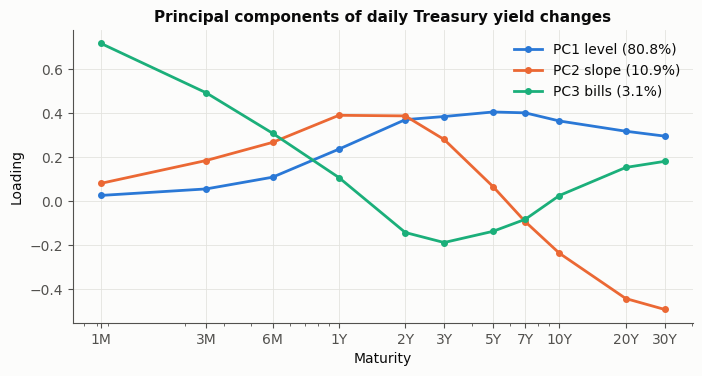

In [13]:
changes = 1e4 * treasury.loc[:VALUATION].iloc[-504:].diff().dropna()
eigval, eigvec = np.linalg.eigh(changes.cov().values)
order = np.argsort(eigval)[::-1]; eigval, eigvec = eigval[order], eigvec[:, order]
eigvec = eigvec * np.sign(eigvec.sum(axis=0))             # sign convention : positive sum
explained = eigval / eigval.sum()
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, name in enumerate(["level", "slope", "bills"]):
    ax.plot(changes.columns, eigvec[:, k], marker="o", ms=4, label=f"PC{k + 1} {name} ({100 * explained[k]:.1f}%)")
ax.set_xscale("log"); ax.set_xticks(changes.columns); ax.set_xticklabels([tenor_label(t) for t in changes.columns])
ax.set_xlabel("Maturity"); ax.set_ylabel("Loading"); ax.set_title("Principal components of daily Treasury yield changes")
ax.legend(); plt.show()

## 4. The SOFR curve (§5) — proxy

SOFR futures and SOFR OIS quotes are not freely available (CME forbids automated collection, see `Data/USD/README.md`).
The SOFR curve is therefore a **proxy**: the Treasury zero curve shifted by a constant spread such that its first
pillar (1 month) matches the overnight SOFR. One curve discounts and projects (SOFR is the collateral rate).

The assumption to keep in mind: in the market, SOFR swap rates sit **below** Treasury yields by an amount that grows
with maturity (negative swap spreads). A constant spread therefore probably **overstates** the SOFR forwards beyond one
year; Section 6.4 measures how much the price depends on it. The jump of the overnight forward at 1 year is an
artefact of the junction between bills (zero-coupon pillars) and coupon bonds in the Treasury inputs: it would
disappear with SOFR futures, which give one pillar per IMM quarter.

In [14]:
curve, spread_bp = sofr_proxy_curve(VALUATION, treasury, sofr)
history = pd.concat([sofr, treasury[1 / 12]], axis=1, keys=["SOFR", "1M bill"]).dropna()
basis = 1e4 * (history["SOFR"] - history["1M bill"])
print(curve)
print(f"SOFR - 1M bill (bp) : today {basis.iloc[-1]:+.1f}, last year mean {basis.iloc[-252:].mean():+.1f}, "
      f"std {basis.iloc[-252:].std():.1f}")

YieldCurve(name='SOFR proxy 2026-10-02 (UST -6.6bp)', method='monotone_convex', pillars=11 from 0.0833333y to 30y)
SOFR - 1M bill (bp) : today -16.0, last year mean -7.4, std 8.5


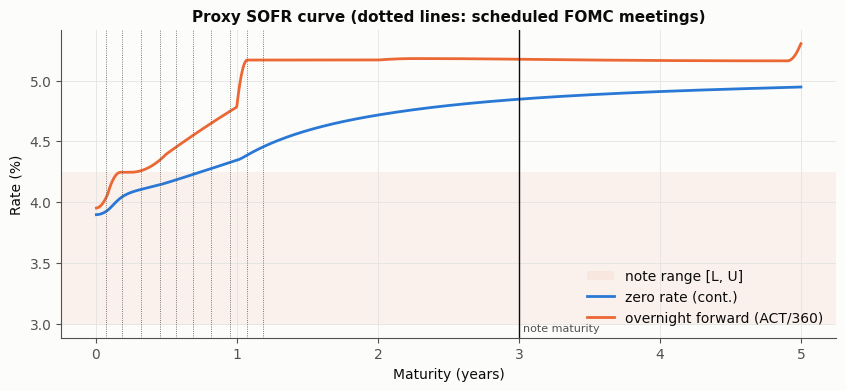

In [15]:
t = np.linspace(1 / 365, 5, 1500)
fig, ax = plt.subplots(figsize=(10, 4))
ax.axhspan(100 * note.lower, 100 * note.upper, color=COLORS[1], alpha=0.07, lw=0, label="note range [L, U]")
ax.plot(t, 100 * curve.zero_rate(t), label="zero rate (cont.)")
ax.plot(t, 100 * curve.forward_rate(t, t + 1 / 365, "simple") * 365 / 360, label="overnight forward (ACT/360)")
for d in fomc["Decision"][fomc["Decision"] > VALUATION]:
    ax.axvline(year_fraction(VALUATION, d), color=MUTED, lw=0.6, ls=":")
ax.axvline(3, color=INK, lw=1); ax.text(3.03, ax.get_ylim()[0] + 0.05, "note maturity", color=MUTED, fontsize=8)
ax.set_xlabel("Maturity (years)"); ax.set_ylabel("Rate (%)")
ax.set_title("Proxy SOFR curve (dotted lines: scheduled FOMC meetings)"); ax.legend(loc="lower right"); plt.show()

**Reading the curve: implied policy path.** Average overnight forward between consecutive FOMC decisions (the new rate
applies from the day after the decision), compared with today's SOFR, in units of 25bp moves. With the proxy curve this
is the path priced by **Treasury bills**, not by SOFR futures: it mixes expectations, term premium and the
bill-SOFR basis.

In [16]:
decisions = list(fomc["Decision"][fomc["Decision"] > VALUATION])
edges = [VALUATION] + [d + pd.Timedelta(days=1) for d in decisions]
rows = []
for start, end in zip(edges[:-1], edges[1:]):
    t1, t2 = year_fraction(VALUATION, start), year_fraction(VALUATION, end)
    fwd = curve.forward_rate(max(t1, 1e-6), t2, "simple") * 365 / 360
    rows.append({"from": start.date(), "to": (end - pd.Timedelta(days=1)).date(), "overnight forward (%)": 100 * fwd,
                 "vs SOFR today (bp)": 1e4 * (fwd - sofr.loc[VALUATION]),
                 "cumulative 25bp moves": (fwd - sofr.loc[VALUATION]) / 0.0025})
pd.DataFrame(rows)

,from,to,overnight forward (%),vs SOFR today (bp),cumulative 25bp moves
0,2026-10-02,2026-10-28,3.9862,10.6198,0.42479
1,2026-10-29,2026-12-09,4.19079,31.0792,1.24317
2,2026-12-10,2027-01-27,4.26015,38.0152,1.52061
3,2027-01-28,2027-03-17,4.30958,42.9584,1.71834
4,2027-03-18,2027-04-28,4.41664,53.6645,2.14658
5,2027-04-29,2027-06-09,4.51325,63.3248,2.53299
6,2027-06-10,2027-07-28,4.61388,73.3877,2.93551
7,2027-07-29,2027-09-15,4.71603,83.6033,3.34413
8,2027-09-16,2027-10-27,4.94558,106.558,4.2623
9,2027-10-28,2027-12-08,5.18377,130.377,5.21507


## 5. Volatility and model (§6–7)

### 5.1 No implied volatility: realized Treasury volatility
Options on SR3 futures (the only public source of SOFR volatility) are CME data. As a substitute, the model is
calibrated on the **realized normal volatility** of daily Treasury yield changes over the last year. This is a
historical (P-measure) volatility, not a market price of optionality: the SABR block of the paper (§6) cannot be done
with the data at hand.

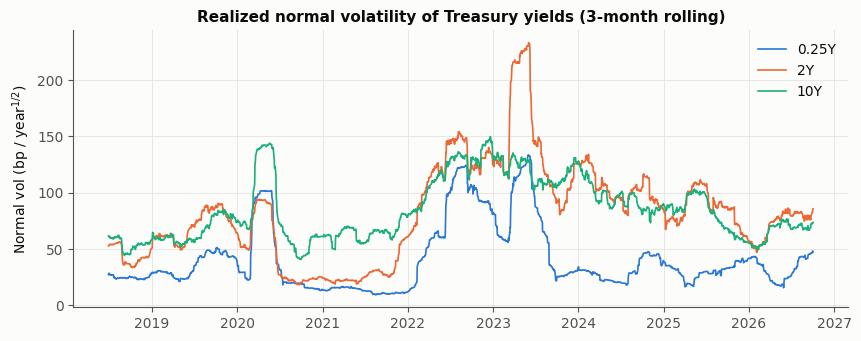

In [17]:
window = treasury.loc[:VALUATION].iloc[-252:]
realized = window.diff().dropna().std() * np.sqrt(252)
rolling = treasury.loc[:VALUATION].diff().rolling(63).std() * np.sqrt(252)
fig, ax = plt.subplots(figsize=(10, 3.6))
for k, tau in enumerate([0.25, 2.0, 10.0]):
    ax.plot(rolling.index, 1e4 * rolling[tau], lw=1.2, color=COLORS[k], label=f"{tau:g}Y")
ax.set_ylabel("Normal vol (bp / year$^{1/2}$)"); ax.set_title("Realized normal volatility of Treasury yields (3-month rolling)")
ax.legend(); plt.show()

### 5.2 Hull-White one-factor calibration
In Hull-White, the instantaneous normal volatility of the $\tau$-maturity zero yield is
$\sigma B(\tau)/\tau$ with $B(\tau) = (1 - e^{-a\tau})/a$: a **decreasing** function of $\tau$. The realized term
structure is **humped** (low at the very short end, anchored by the policy rate, maximal around 2–5 years): a single
factor cannot reproduce it, which is the first argument for the **two-factor** model (G2++ with negative correlation
between the factors produces a hump).

The one-factor model is calibrated where the note lives: $a$ is fixed at 3% and $\sigma$ fitted to the 1Y–3Y realized
vols.

HullWhite(a=0.0300, sigma=69.7bp)


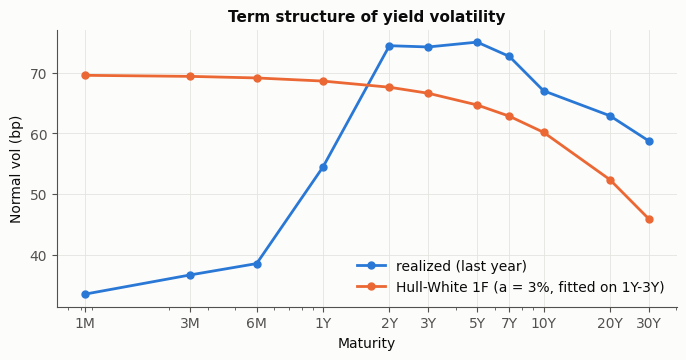

In [18]:
B = lambda a, tau: (1 - np.exp(-a * tau)) / a
tenors = np.array([1.0, 2.0, 3.0])
a_hw = 0.03
fit = least_squares(lambda p: p[0] * B(a_hw, tenors) / tenors - realized[tenors].values, [0.008])
sigma_hw = float(fit.x[0])
hw = HullWhite(curve, a=a_hw, sigma=sigma_hw)
print(hw)
taus = np.array(realized.index)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(taus, 1e4 * realized.values, marker="o", ms=5, label="realized (last year)")
ax.plot(taus, 1e4 * sigma_hw * B(a_hw, taus) / taus, marker="o", ms=5, label=f"Hull-White 1F (a = {a_hw:.0%}, fitted on 1Y-3Y)")
ax.set_xscale("log"); ax.set_xticks(taus); ax.set_xticklabels([tenor_label(t) for t in taus])
ax.set_xlabel("Maturity"); ax.set_ylabel("Normal vol (bp)"); ax.set_title("Term structure of yield volatility")
ax.legend(); plt.show()

## 6. Pricing (§8)

Three methods on the same curve and model:
1. **Static replication** of the non-callable note, Eq. (4): Bachelier digitals and calls at $L$ and $U$ with the
   normal vol of the overnight rate implied by Hull-White, $\sigma\sqrt{(1-e^{-2at})/(2at)}$;
2. **Monte Carlo** on the exact Hull-White simulation, every SOFR fixing simulated, and **Longstaff-Schwartz** for
   the call (estimated on one set of paths, applied out of sample on another);
3. **Exact backward induction** on a grid (one-factor only): conditionally on the state at the start of a period,
   the coupon is in closed form, so the Bermudan call needs no simulation.

### 6.1 Non-callable and callable note

In [19]:
grid_pricer = HullWhiteGridPricer(hw, note, VALUATION, sofr)
start = time.time()
grid_nc, _ = grid_pricer.price(callable=False)
grid_c, call_region = grid_pricer.price(callable=True)
grid_time = time.time() - start
repl = replication_value(note, curve, hull_white_normal_vol(hw), VALUATION, sofr)
start = time.time()
mc_in = monte_carlo(hw, note, VALUATION, sofr, n_paths=40_000, seed=1)
mc = monte_carlo(hw, note, VALUATION, sofr, n_paths=40_000, seed=2, policy=mc_in["policy"])
mc_time = time.time() - start
summary = pd.DataFrame({
    "non-callable": [repl, grid_nc, mc["non-callable"]],
    "callable": [np.nan, grid_c, mc["callable"]],
    "issuer call": [np.nan, grid_nc - grid_c, mc["issuer call"]],
    "std error": [np.nan, np.nan, mc["callable stderr"]]},
    index=["static replication (Bachelier, HW vol)", "exact grid (HW 1F)", "Monte Carlo + LSM out of sample (HW 1F)"])
print(f"grid {grid_time:.1f}s | Monte Carlo (2 x 40,000 paths) {mc_time:.1f}s | LSM in-sample callable {100 * mc_in['callable']:.4f}%")
(100 * summary).round(4).rename(columns=lambda c: c + " (% of N)")

grid 1.0s | Monte Carlo (2 x 40,000 paths) 8.6s | LSM in-sample callable 90.7400%


,non-callable (% of N),callable (% of N),issuer call (% of N),std error (% of N)
"static replication (Bachelier, HW vol)",90.7973,NaN,NaN,NaN
exact grid (HW 1F),90.8048,90.7628,0.042,NaN
Monte Carlo + LSM out of sample (HW 1F),90.8136,90.7731,0.0405,0.0108


The three methods agree on the non-callable note to within about 1bp of notional (Monte Carlo standard error ~1bp,
grid discretisation ~0.5bp, Section 6.5). Longstaff-Schwartz gives a
slightly **lower** value of the issuer's call than the exact grid: a regressed exercise policy is sub-optimal, so it
under-estimates the option of the issuer (and over-estimates the note).

**The note is worth about 91% of par**, and the call is almost worthless. The reason is the curve: the overnight
forwards rise above the upper bound of 4.25% within a few months (Section 4), so most future days are expected
out of range. The issuer only calls when the note is worth more than par, which requires rates to fall well back
into the range: below about 3.6-4.0% of overnight SOFR at the last notice dates, and below 0% at the first ones, where
three years of coupons remain to be earned (call regions below; the lower end is the edge of the grid).

In [20]:
pd.DataFrame({"call date": list(mc["call probabilities"]),
              "LSM call probability (%)": [100 * v for v in mc["call probabilities"].values()],
              "grid: calls if SOFR at notice in (%)": [f"[{100 * call_region[d][0]:.2f}, {100 * call_region[d][1]:.2f}]"
                                                       if d in call_region else "never" for d in mc["call probabilities"]]})

,call date,LSM call probability (%),grid: calls if SOFR at notice in (%)
0,2027-10-04,0,"[-3.34, -0.95]"
1,2028-01-03,0,"[-2.94, -0.50]"
2,2028-04-03,0,"[-2.94, -0.44]"
3,2028-07-03,0,"[-2.94, -0.39]"
4,2028-10-02,3.0625,"[-2.93, 3.60]"
5,2029-01-02,4.5875,"[-2.92, 3.77]"
6,2029-04-02,5.2175,"[-2.92, 3.88]"
7,2029-07-02,4.595,"[-2.92, 3.99]"


### 6.2 Decomposition, Eq. (6)
Zero-coupon bond + strip of daily calls and digitals − Bermudan call of the issuer.

In [21]:
coupons, zc = replication_value(note, curve, hull_white_normal_vol(hw), VALUATION, sofr, by_period=True)
decomposition = pd.Series({"zero-coupon bond N P(0,T_n)": zc, "strip of calls and digitals": coupons.sum(),
                           "issuer call (grid)": -(grid_nc - grid_c), "callable note": zc + coupons.sum() - (grid_nc - grid_c)})
(N * decomposition).map("{:,.0f}".format).rename("USD").to_frame()

,USD
"zero-coupon bond N P(0,T_n)","8,645,511"
strip of calls and digitals,"434,220"
issuer call (grid),"-4,200"
callable note,"9,075,530"


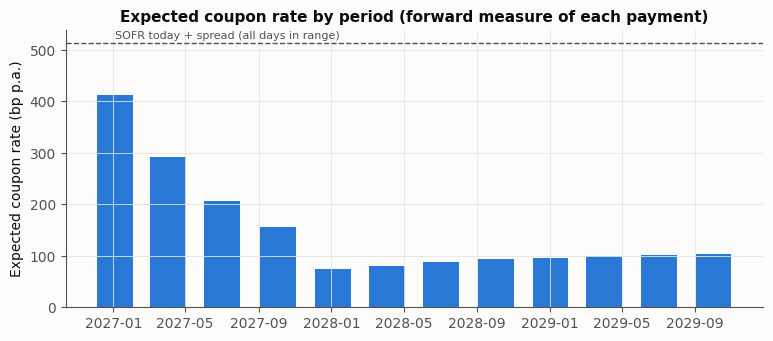

In [22]:
grid = NoteGrid(note, VALUATION, sofr)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(note.coupon_dates, 1e4 * coupons / curve.discount(grid.pay_times) * 360 / np.array([p["days"] for p in note.periods]),
       width=60, color=COLORS[0])
ax.axhline(1e4 * (sofr.loc[VALUATION] + note.spread), color=MUTED, ls="--", lw=1)
ax.text(note.coupon_dates[0], 1e4 * (sofr.loc[VALUATION] + note.spread) + 8, "SOFR today + spread (all days in range)",
        color=MUTED, fontsize=8)
ax.set_ylabel("Expected coupon rate (bp p.a.)"); ax.set_title("Expected coupon rate by period (forward measure of each payment)")
plt.show()

### 6.3 Smile: a hypothetical skew
Without option data the smile cannot be calibrated. Eq. (5) still shows how much it can matter: with a linear smile
$\sigma_N(K) = \sigma_N + \text{skew}\,(K - F)$, each digital gains the term $-\text{skew}\,\sqrt t\,\varphi(d)$.
The skews below are **hypothetical**, in bp of normal vol per 1% of strike.

In [23]:
rows = {}
flat = replication_value(note, curve, hull_white_normal_vol(hw), VALUATION, sofr)
for skew_bp in [-20, -10, 0, 10, 20]:
    value = replication_value(note, curve, hull_white_normal_vol(hw), VALUATION, sofr, skew=skew_bp * 1e-4 / 0.01)
    rows[f"{skew_bp:+d}bp per 1%"] = {"non-callable (% of N)": 100 * value, "vs flat smile (USD)": N * (value - flat)}
pd.DataFrame(rows).T

,non-callable (% of N),vs flat smile (USD)
-20bp per 1%,89.8989,"-89,836.4"
-10bp per 1%,90.3374,"-45,993.1"
+0bp per 1%,90.7973,0
+10bp per 1%,91.1379,"34,061.3"
+20bp per 1%,91.2349,"43,761.4"


### 6.4 What drives the price
**Range placement, spread and volatility.** The upper bound matters most: the forwards sit just above it.

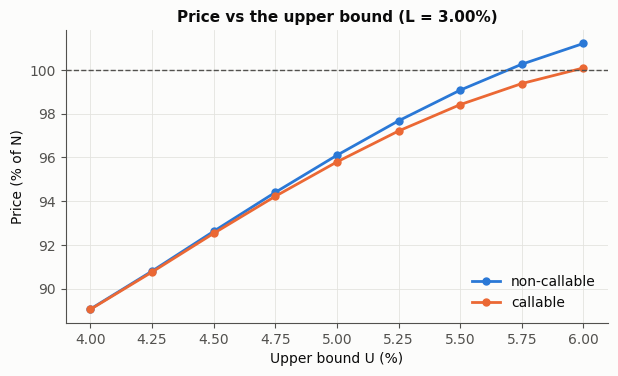

In [24]:
uppers = np.arange(0.04, 0.0601, 0.0025)
values = {"non-callable": [], "callable": []}
for U in uppers:
    g = HullWhiteGridPricer(hw, note.with_terms(upper=U), VALUATION, sofr)
    values["non-callable"].append(g.price(False)[0]); values["callable"].append(g.price(True)[0])
fig, ax = plt.subplots(figsize=(7, 3.8))
for k, (name, v) in enumerate(values.items()):
    ax.plot(100 * uppers, 100 * np.array(v), marker="o", ms=5, label=name, color=COLORS[k])
ax.axhline(100, color=MUTED, lw=1, ls="--")
ax.set_xlabel("Upper bound U (%)"); ax.set_ylabel("Price (% of N)"); ax.set_title("Price vs the upper bound (L = 3.00%)")
ax.legend(); plt.show()

In [25]:
rows = {}
for name, kwargs in {"base": {}, "spread 2.50%": {"spread": 0.025}, "range [3.75%, 5.25%]": {"lower": 0.0375, "upper": 0.0525},
                     "range [3.75%, 5.25%], spread 2.50%": {"lower": 0.0375, "upper": 0.0525, "spread": 0.025}}.items():
    for vol_name, model in {"sigma": hw, "sigma x 0.5": HullWhite(curve, a_hw, 0.5 * sigma_hw)}.items():
        g = HullWhiteGridPricer(model, note.with_terms(**kwargs), VALUATION, sofr)
        nc, c = g.price(False)[0], g.price(True)[0]
        rows[(name, vol_name)] = {"non-callable (%)": 100 * nc, "callable (%)": 100 * c, "issuer call (bp of N)": 1e4 * (nc - c)}
pd.DataFrame(rows).T

non-callable (%)  \
base                               sigma                 90.8048   
                                   sigma x 0.5           89.5777   
spread 2.50%                       sigma                 91.8673   
                                   sigma x 0.5           90.3164   
range [3.75%, 5.25%]               sigma                 96.5198   
                                   sigma x 0.5           99.4055   
range [3.75%, 5.25%], spread 2.50% sigma                 98.7171   
                                   sigma x 0.5           102.186   

                                                callable (%)  \
base                               sigma             90.7628   
                                   sigma x 0.5       89.5555   
spread 2.50%                       sigma             91.6677   
                                   sigma x 0.5         90.25   
range [3.75%, 5.25%]               sigma             96.3719   
                                   sigma x 0.5        98.683   
range [3.75%, 5.25%], spread 2.50% sigma             97.9899   
                                   sigma x 0.5       100.298   

                                                issuer call (bp of N)  
base                               sigma                      4.20002  
                                   sigma x 0.5                2.21908  
spread 2.50%                       sigma                       19.962  
                                   sigma x 0.5                6.63687  
range [3.75%, 5.25%]               sigma                       14.783  
                                   sigma x 0.5                72.2515  
range [3.75%, 5.25%], spread 2.50% sigma                       72.711  
                                   sigma x 0.5                188.757

**Dependence on the curve assumption.** The proxy curve uses the SOFR - Treasury spread at 1 month for every maturity.
If SOFR forwards are in fact below the Treasury-implied ones (negative swap spreads), more days fall in range:

In [26]:
rows = {}
for extra in [0, -10, -25, -50]:
    c_shift, _ = sofr_proxy_curve(VALUATION, treasury, sofr, spread_bp=spread_bp + extra)
    g = HullWhiteGridPricer(HullWhite(c_shift, a_hw, sigma_hw), note, VALUATION, sofr)
    nc, c = g.price(False)[0], g.price(True)[0]
    rows[f"{extra:+d}bp"] = {"non-callable (%)": 100 * nc, "callable (%)": 100 * c, "issuer call (bp of N)": 1e4 * (nc - c)}
pd.DataFrame(rows).T.rename_axis("extra SOFR - Treasury spread")

,non-callable (%),callable (%),issuer call (bp of N)
extra SOFR - Treasury spread,,,
+0bp,90.8048,90.7628,4.20002
-10bp,91.6475,91.5996,4.79347
-25bp,92.8455,92.7881,5.74158
-50bp,94.5895,94.5155,7.40029


### 6.5 Numerical study: convergence

In [27]:
rows = {}
for n in [5_000, 10_000, 20_000, 40_000, 80_000]:
    r = monte_carlo(hw, note, VALUATION, sofr, n_paths=n, seed=7)
    rows[n] = {"non-callable error vs grid (bp of N)": 1e4 * (r["non-callable"] - grid_nc),
               "non-callable std error (bp)": 1e4 * r["non-callable stderr"],
               "callable error vs grid (bp)": 1e4 * (r["callable"] - grid_c)}
pd.DataFrame(rows).T.rename_axis("paths")

,non-callable error vs grid (bp of N),non-callable std error (bp),callable error vs grid (bp)
paths,,,
5000,8.97673,3.18857,8.75758
10000,0.957666,2.24104,0.713281
20000,1.22069,1.5818,1.33066
40000,1.02418,1.11417,0.83225
80000,-0.494034,0.791499,-0.557121


In [28]:
rows = {}
for n_grid in [101, 201, 301, 601]:
    for n_quad in [16, 48]:
        g = HullWhiteGridPricer(hw, note, VALUATION, sofr, n_grid=n_grid, n_quad=n_quad)
        rows[(n_grid, n_quad)] = {"non-callable (%)": 100 * g.price(False)[0], "callable (%)": 100 * g.price(True)[0]}
pd.DataFrame(rows).T.rename_axis(["grid points", "quadrature nodes"])

non-callable (%)  callable (%)
grid points quadrature nodes                                
101         16                         90.8185       90.7905
            48                         90.8327       90.8018
201         16                         90.8025       90.7653
            48                         90.8027       90.7673
301         16                         90.8002       90.7579
            48                         90.8048       90.7628
601         16                         90.7938        90.752
            48                         90.8011       90.7591

## 7. Greeks (§9)

Computed with the exact grid (smooth in the inputs, no Monte Carlo noise), per USD 10m notional, from the point of view
of the **investor** (long the note). Curve risk: the Treasury par yields are bumped and the curve re-bootstrapped, the
SOFR - Treasury spread being kept fixed; the Hull-White parameters are kept fixed.

In [29]:
def note_value(treasury_df=treasury, sigma=sigma_hw, note_=note):
    c, _ = sofr_proxy_curve(VALUATION, treasury_df, sofr, spread_bp=spread_bp)
    g = HullWhiteGridPricer(HullWhite(c, a_hw, sigma), note_, VALUATION, sofr)
    return np.array([g.price(False)[0], g.price(True)[0]])

def bumped(bp, tenor=None):
    out = treasury.copy()
    cols = out.columns if tenor is None else [tenor]
    out.loc[VALUATION, cols] += bp * 1e-4
    return out

base = note_value()
up, down = note_value(bumped(1)), note_value(bumped(-1))
vega_up = note_value(sigma=sigma_hw + 1e-4)
greeks = pd.DataFrame({"value": N * base, "DV01 (per +1bp)": N * (up - down) / 2,
                       "gamma (per bp^2)": N * (up - 2 * base + down), "vega (per +1bp of sigma)": N * (vega_up - base)},
                      index=["non-callable", "callable"])
greeks.round(0)

,value,DV01 (per +1bp),gamma (per bp^2),vega (per +1bp of sigma)
non-callable,9.08048e+06,"-8,313",-26,"1,530"
callable,9.07628e+06,"-8,258",-31,"1,662"


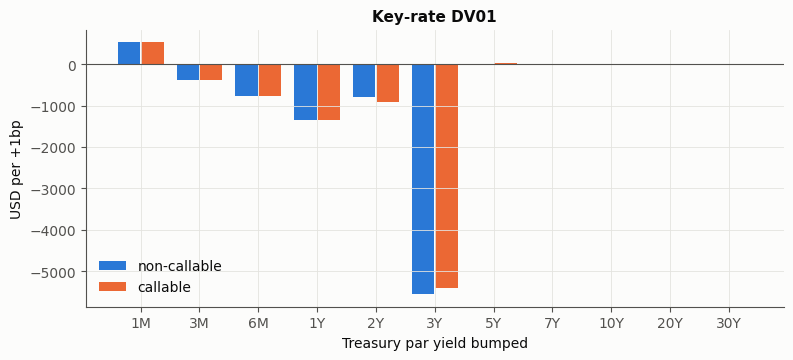

In [30]:
key = {}
for tenor in treasury.columns:
    u, d = note_value(bumped(1, tenor)), note_value(bumped(-1, tenor))
    key[tenor_label(tenor)] = N * (u - d) / 2
key = pd.DataFrame(key, index=["non-callable", "callable"]).T
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(key))
ax.bar(x - 0.2, key["non-callable"], width=0.38, label="non-callable", color=COLORS[0])
ax.bar(x + 0.2, key["callable"], width=0.38, label="callable", color=COLORS[1])
ax.set_xticks(x); ax.set_xticklabels(key.index); ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xlabel("Treasury par yield bumped"); ax.set_ylabel("USD per +1bp"); ax.set_title("Key-rate DV01")
ax.legend(); plt.show()

**Gamma near the bounds.** Value against a parallel shift of the curve. The price rises steeply as rates fall back
into the range (the forwards cross U), flattens once most forwards are inside it, and starts to fall again when they
approach L from above. The note never gets close to par, so the call barely changes the profile: with this term sheet,
the risk of the investor is a large negative DV01 and a positive vega (the forwards being outside the range, more
volatility brings more days into it).

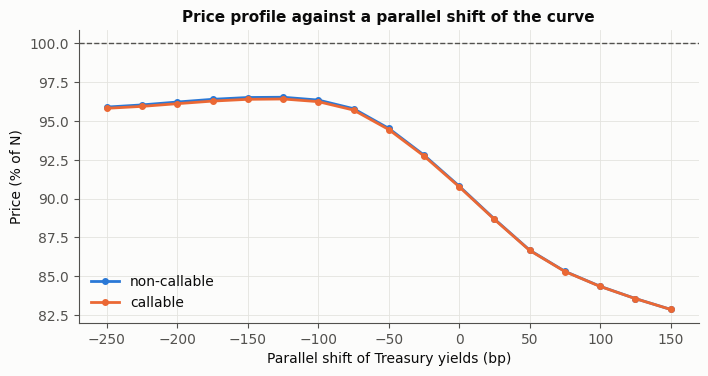

In [31]:
shifts = np.arange(-250, 151, 25)
profile = np.array([note_value(bumped(b)) for b in shifts])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(shifts, 100 * profile[:, 0], marker="o", ms=4, label="non-callable")
ax.plot(shifts, 100 * profile[:, 1], marker="o", ms=4, label="callable")
ax.axhline(100, color=MUTED, lw=1, ls="--")
ax.set_xlabel("Parallel shift of Treasury yields (bp)"); ax.set_ylabel("Price (% of N)")
ax.set_title("Price profile against a parallel shift of the curve"); ax.legend(); plt.show()

## 8. Summary and next steps

- **Done with public data:** exact schedule and payoff, market history and backtest, Treasury foundations validated
  against QuantLib, a proxy SOFR curve, a one-factor model, three pricing methods that agree, Greeks.
- **Main findings so far:** with the October 2026 curve the forwards are above the 4.25% bound, so the note is worth
  about 91% of par and the issuer's call is almost worthless; the price depends strongly on the curve assumption and on
  the placement of the range; the realized volatility term structure is humped, out of reach of a one-factor model.
- **Missing data (CME):** SR1 / SR3 futures for a market SOFR curve (§5) and options on SR3 for the smile and SABR
  (§6), and the history needed for the hedge backtest (§9.2).
- **Next:** the two-factor model in `Fixed_Income_Models/hull_white_2F.py` with the `simulate` / `bond_price`
  interface, priced by `monte_carlo` and compared with the one-factor grid.